<a href="https://colab.research.google.com/github/samikshagame027-cpu/AI-ML-Week1-ML-Basics/blob/main/AI_ML_Week2_Classification_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

print("Week 2 - Classification Models")
print("Setup Successful!")

Week 2 - Classification Models
Setup Successful!


In [ ]:
import seaborn as sns

# Load Titanic dataset
df = sns.load_dataset("titanic")

# Select useful columns
df = df[["survived", "pclass", "sex", "age", "fare"]]

# Remove missing values
df = df.dropna()

# Convert sex into numeric values
df["sex"] = df["sex"].map({"male": 0, "female": 1})

# Display first 10 rows
print(df.head(10))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

    survived  pclass  sex   age     fare
0          0       3    0  22.0   7.2500
1          1       1    1  38.0  71.2833
2          1       3    1  26.0   7.9250
3          1       1    1  35.0  53.1000
4          0       3    0  35.0   8.0500
6          0       1    0  54.0  51.8625
7          0       3    0   2.0  21.0750
8          1       3    1  27.0  11.1333
9          1       2    1  14.0  30.0708
10         1       3    1   4.0  16.7000
Dataset loaded successfully!
Dataset shape: (714, 5)


In [ ]:
# Select input and output
X = df[["pclass", "sex", "age", "fare"]]
y = df["survived"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Model Trained Successfully!")
print("Accuracy Score:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Logistic Regression Model Trained Successfully!
Accuracy Score: 0.7552447552447552
Accuracy Percentage: 75.52447552447552 %


Confusion Matrix:
[[68 19]
 [16 40]]

Accuracy Score: 0.7552447552447552


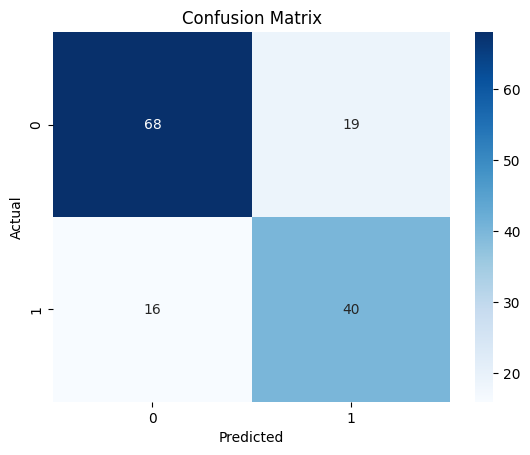

In [4]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy Score:", accuracy_score(y_test, y_pred))

# Display confusion matrix as a graph
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [5]:
# Decision Tree Model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

# KNN Model
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)
knn_accuracy = accuracy_score(y_test, knn_pred)

# Compare accuracy
print("Decision Tree Accuracy:", dt_accuracy * 100, "%")
print("KNN Accuracy:", knn_accuracy * 100, "%")

if dt_accuracy > knn_accuracy:
    print("Decision Tree performs better.")
elif knn_accuracy > dt_accuracy:
    print("KNN performs better.")
else:
    print("Both models have equal accuracy.")

Decision Tree Accuracy: 71.32867132867133 %
KNN Accuracy: 65.73426573426573 %
Decision Tree performs better.


In [6]:
# Test different max_depth values

depths = [1, 2, 3, 4, 5, 6,  None]

for depth in depths:
    dt = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    dt.fit(X_train, y_train)
    pred = dt.predict(X_test)

    acc = accuracy_score(y_test, pred)

    print("Max Depth:", depth,
          "| Accuracy:", round(acc * 100, 2), "%")

Max Depth: 1 | Accuracy: 73.43 %
Max Depth: 2 | Accuracy: 73.43 %
Max Depth: 3 | Accuracy: 74.13 %
Max Depth: 4 | Accuracy: 75.52 %
Max Depth: 5 | Accuracy: 72.03 %
Max Depth: 6 | Accuracy: 74.83 %
Max Depth: None | Accuracy: 71.33 %
